In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import LinearRegression, Ridge, Lasso, HuberRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
import warnings
warnings.filterwarnings('ignore')

data = fetch_california_housing()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['Price'] = data.target
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Price
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


R2 Score: 0.497


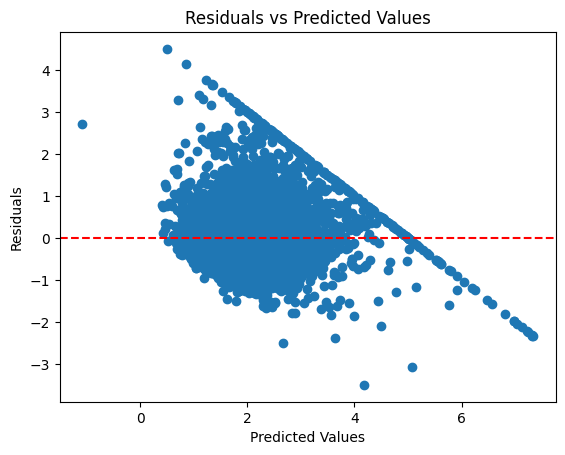

In [2]:
X = df[['MedInc', 'AveRooms', 'HouseAge']]
Y = df['Price']

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, Y_train)
preds = model.predict(X_test)

print(f"R2 Score: {r2_score(Y_test, preds):.3f}")

#residuals
residuals = Y_test - preds
plt.scatter(preds, residuals)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Predicted Values')
plt.ylabel('Residuals')
plt.title('Residuals vs Predicted Values')
plt.show()

In [3]:
print("Intercept:", model.intercept_)

print("\nCoefficients:")
for feature, coef in zip(X.columns, model.coef_):
    print(f"{feature}: {coef:.3f}")

Intercept: 0.017295645283372796

Coefficients:
MedInc: 0.445
AveRooms: -0.028
HouseAge: 0.017


In [3]:
#inject fake outliers - house price 50x normal
df_broken = df.copy()
df_broken.loc[0:50, 'Price'] = 50.0

X_broken = df_broken[['MedInc', 'AveRooms', 'HouseAge']]
Y_broken = df_broken['Price']

X_train_broken, X_test_broken, Y_train_broken, Y_test_broken = train_test_split(X_broken, Y_broken, test_size=0.2, random_state=42)

# Normal LR vs Robust LR
lr = LinearRegression().fit(X_train_broken, Y_train_broken)
huber = HuberRegressor().fit(X_train_broken, Y_train_broken)

print(f"R2 Score (Linear Regression): {r2_score(Y_test_broken, lr.predict(X_test_broken)):.3f}")
print(f"R2 Score (Huber Regressor): {r2_score(Y_test_broken, huber.predict(X_test_broken)):.3f}")

R2 Score (Linear Regression): 0.070
R2 Score (Huber Regressor): 0.052


In [4]:
df_leak = df.copy()
df_leak['leaked_feature'] = df_leak['Price'] * 0.99 + np.random.normal(0, 0.1, len(df))

X_leak = df_leak[['MedInc', 'AveRooms', 'leaked_feature']]
Y_leak = df_leak['Price']

X_tr, X_te, y_tr, y_te = train_test_split(X_leak, Y_leak, test_size=0.2, random_state=42)

model_leak = LinearRegression().fit(X_tr, y_tr)
print(f"R² WITH leakage: {r2_score(y_te, model_leak.predict(X_te)):.3f}")


R² WITH leakage: 0.992


In [8]:
df_multi = df.copy()
df_multi['MedInc_copy'] = df_multi['MedInc'] * 1.01 + np.random.normal(0, 0.01, len(df_multi))

X_multi = df_multi[['MedInc', 'MedInc_copy', 'AveRooms']]
Y_multi = df_multi['Price']

X_tr_multi, X_te_multi, y_tr_multi, y_te_multi = train_test_split(X_multi, Y_multi, test_size=0.2, random_state=42)

model_multi = LinearRegression().fit(X_tr_multi, y_tr_multi)
ridge_multi = Ridge(alpha=1.0).fit(X_tr_multi, y_tr_multi)
lasso_multi = Lasso(alpha=0.1).fit(X_tr_multi, y_tr_multi)

print("Normal LR coeff:", model_multi.coef_)
print("Ridge LR coeff:", ridge_multi.coef_)
print("Lasso LR coeff:", lasso_multi.coef_)

from statsmodels.stats.outliers_influence import variance_inflation_factor
vif = []
for i in range(X_multi.shape[1]):
    vif.append(variance_inflation_factor(X_multi.values, i))
print(f"VIF values: {vif}")
print(f"R² WITH multicollinearity: {r2_score(y_te_multi, model_multi.predict(X_te_multi)):.3f}")
print(f"R² WITH Ridge: {r2_score(y_te_multi, ridge_multi.predict(X_te_multi)):.3f}")
print(f"R² WITH Lasso: {r2_score(y_te_multi, lasso_multi.predict(X_te_multi)):.3f}")

Normal LR coeff: [ 1.26525316 -0.82081988 -0.04018197]
Ridge LR coeff: [ 0.69047235 -0.25171846 -0.04017082]
Lasso LR coeff: [ 0.150918    0.24376977 -0.01213028]
VIF values: [np.float64(187623.86394067484), np.float64(187620.24157237363), np.float64(4.318418618112351)]
R² WITH multicollinearity: 0.464
R² WITH Ridge: 0.464
R² WITH Lasso: 0.461
